# 3. Exploratory Data Analysis with Visualizations

In [4]:

from pathlib import Path
import json
import requests
import pandas as pd

# Step 1: Find any existing launch JSON file
root = Path("/content")
matches = list(root.rglob("spacex_launches.json"))

print("Existing launch files:", [str(p) for p in matches[:10]])

DATA_DIR = Path("/content/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)
launch_file = DATA_DIR / "spacex_launches.json"

# Step 2: Reuse an existing file if found
if matches:
    source = matches[0]
    if source.resolve() != launch_file.resolve():
        launch_file.write_bytes(source.read_bytes())
    print("Reused launch data:", launch_file)

else:
    # Step 3: Download fresh data if no file exists
    api_bases = [
        "https://api.spacexdata.com/v4",
        "https://gateway.pipeworx.io/spacex/v4",
    ]

    launches = None
    errors = []

    for base in api_bases:
        try:
            response = requests.get(
                f"{base}/launches",
                timeout=30
            )
            response.raise_for_status()
            data = response.json()

            if isinstance(data, list) and len(data) > 0:
                launches = data
                print("Downloaded from:", base)
                break

            errors.append(f"{base}: unexpected or empty response")

        except Exception as e:
            errors.append(f"{base}: {type(e).__name__}: {e}")

    if launches is None:
        print("\nUnable to obtain launch data:")
        print("\n".join(errors))
        raise RuntimeError(
            "No launch dataset is available. Check the API errors above "
            "or upload your SpaceX launch JSON/CSV dataset to Colab."
        )

    launch_file.write_text(
        json.dumps(launches, indent=2),
        encoding="utf-8"
    )

# Step 4: Verify the saved file
with open(launch_file, "r", encoding="utf-8") as f:
    launches = json.load(f)

launch_df = pd.json_normalize(launches)

print("\nSUCCESS")
print("Saved file:", launch_file)
print("Launch records:", len(launch_df))
print("Columns:", launch_df.columns.tolist())

display(launch_df.head())


Existing launch files: []
Downloaded from: https://gateway.pipeworx.io/spacex/v4

SUCCESS
Saved file: /content/data/spacex_launches.json
Launch records: 101
Columns: ['name', 'status', 'success', 'date_utc', 'pad', 'rocket', 'details', 'links.article', 'links.webcast', 'links.wikipedia']


,name,status,success,date_utc,pad,rocket,details,links.article,links.webcast,links.wikipedia
0,Falcon Heavy | NROL-97,Launch Successful,True,2026-10-02T03:54:00Z,NaN,NaN,NaN,NaN,NaN,NaN
1,Falcon 9 Block 5 | Transporter 18 (Dedicated S...,Launch Successful,True,2026-10-01T18:32:00Z,NaN,NaN,NaN,NaN,NaN,NaN
2,Falcon 9 Block 5 | Crew-13,Launch Successful,True,2026-10-01T15:10:06Z,NaN,NaN,NaN,NaN,NaN,NaN
3,Starship | Starlink Group 31-1 (Starship Fligh...,Launch Successful,True,2026-09-28T12:48:59Z,NaN,NaN,NaN,NaN,NaN,NaN
4,Falcon 9 Block 5 | USSF-385,Launch Successful,True,2026-09-26T14:00:54Z,NaN,NaN,NaN,NaN,NaN,NaN


Built and saved a basic cleaned dataset.


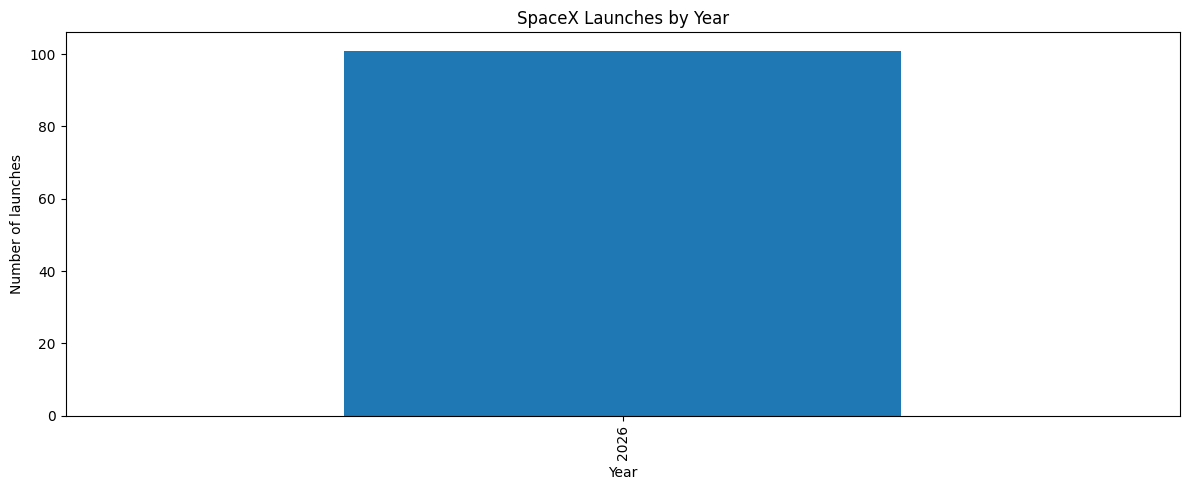

In [6]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import requests

DATA_DIR = Path("/content/data")
cleaned_file = DATA_DIR / "spacex_launches_cleaned.csv"
raw_file = DATA_DIR / "spacex_launches.json"

# Load the cleaned dataset if available
if cleaned_file.exists():
    df = pd.read_csv(cleaned_file)
    print("Loaded cleaned dataset.")

elif raw_file.exists():
    # Rebuild a basic analysis dataset from raw launch records
    with open(raw_file, "r", encoding="utf-8") as f:
        launches = json.load(f)

    launch_df = pd.json_normalize(launches)
    df = pd.DataFrame({
        "date_utc": pd.to_datetime(
            launch_df.get(
                "date_utc",
                pd.Series([None] * len(launch_df))
            ),
            errors="coerce",
            utc=True
        ),
        "upcoming": launch_df.get(
            "upcoming",
            pd.Series([False] * len(launch_df))
        ),
        "success": launch_df.get(
            "success",
            pd.Series([np.nan] * len(launch_df))
        )
    })

    df = df[df["upcoming"] != True].copy()
    df["year"] = df["date_utc"].dt.year
    df.to_csv(cleaned_file, index=False)
    print("Built and saved a basic cleaned dataset.")

else:
    raise FileNotFoundError(
        "Neither cleaned CSV nor raw launch JSON exists in /content/data. "
        "Run the data collection cell successfully first."
    )

# Ensure year exists
if "year" not in df.columns:
    if "date_utc" not in df.columns:
        raise ValueError("Dataset has no 'year' or 'date_utc' column.")
    df["date_utc"] = pd.to_datetime(df["date_utc"], errors="coerce", utc=True)
    df["year"] = df["date_utc"].dt.year

# Plot launches per year
year_counts = df.dropna(subset=["year"]).groupby("year").size()

ax = year_counts.plot(
    kind="bar",
    figsize=(12, 5),
    title="SpaceX Launches by Year"
)
ax.set_xlabel("Year")
ax.set_ylabel("Number of launches")
plt.tight_layout()
plt.show()


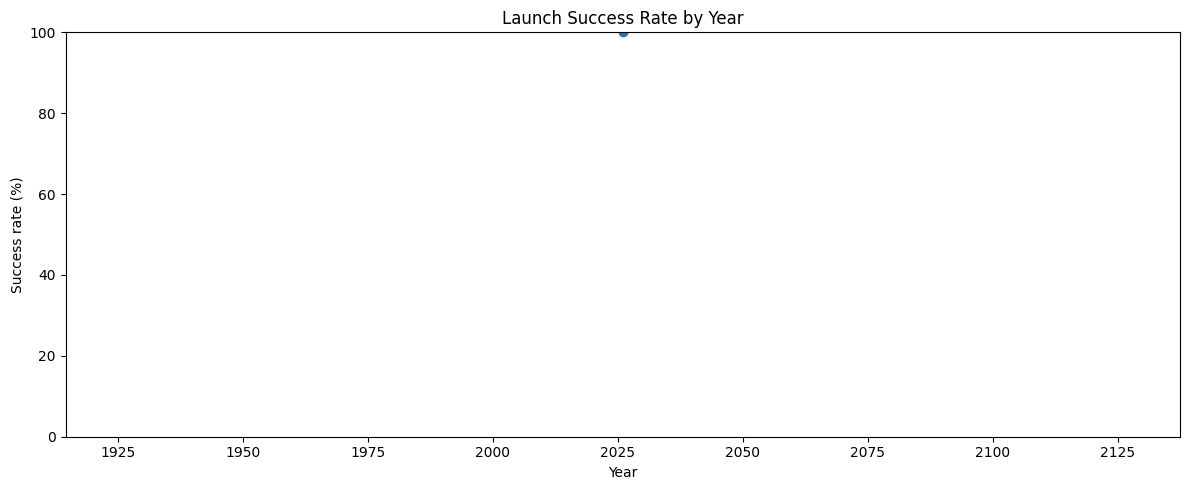

In [7]:
# 2. Success rate per year, based only on known outcomes
known = df.dropna(subset=["success"]).copy()
known["success"] = known["success"].astype(int)
year_rate = known.groupby("year")["success"].mean().mul(100)
ax = year_rate.plot(kind="line", marker="o", figsize=(12,5), title="Launch Success Rate by Year")
ax.set_xlabel("Year"); ax.set_ylabel("Success rate (%)"); ax.set_ylim(0,100)
plt.tight_layout(); plt.show()

In [8]:
# 3. Launch counts by launchpad
if "launchpad_name" in df.columns:
    counts = df["launchpad_name"].fillna("Unknown").value_counts().sort_values()
    ax = counts.plot(kind="barh", figsize=(10,5), title="Launch Records by Launch Site")
    ax.set_xlabel("Launch count"); ax.set_ylabel("Launch site")
    plt.tight_layout(); plt.show()

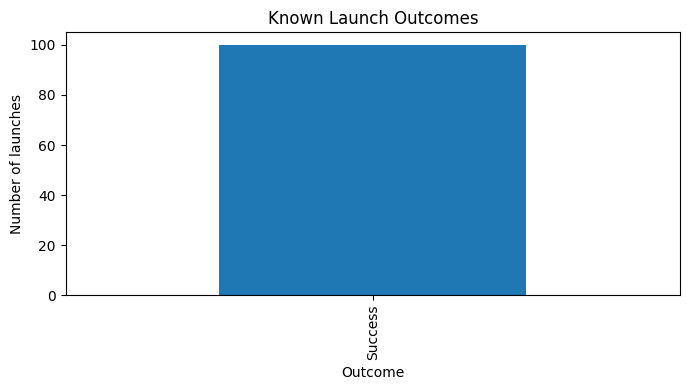

In [9]:
# 4. Outcome distribution
outcomes = known["success"].map({1:"Success",0:"Failure"}).value_counts()
ax = outcomes.plot(kind="bar", figsize=(7,4), title="Known Launch Outcomes")
ax.set_xlabel("Outcome"); ax.set_ylabel("Number of launches")
plt.tight_layout(); plt.show()

In [10]:
# 5. Payload mass versus flight number, colored by outcome
if "payload_mass_kg" in df.columns:
    plot_df = df.dropna(subset=["payload_mass_kg","success"]).copy()
    plot_df["outcome"] = plot_df["success"].map({1:"Success",0:"Failure"})
    for label, group in plot_df.groupby("outcome"):
        plt.scatter(group["payload_mass_kg"], group["flight_number"], label=label, alpha=.7)
    plt.xlabel("Payload mass (kg)"); plt.ylabel("Flight number")
    plt.title("Payload Mass vs Flight Number and Outcome"); plt.legend()
    plt.tight_layout(); plt.show()

/usr/local/lib/python3.13/dist-packages/pandas/plotting/_matplotlib/core.py:1567: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(left, right)


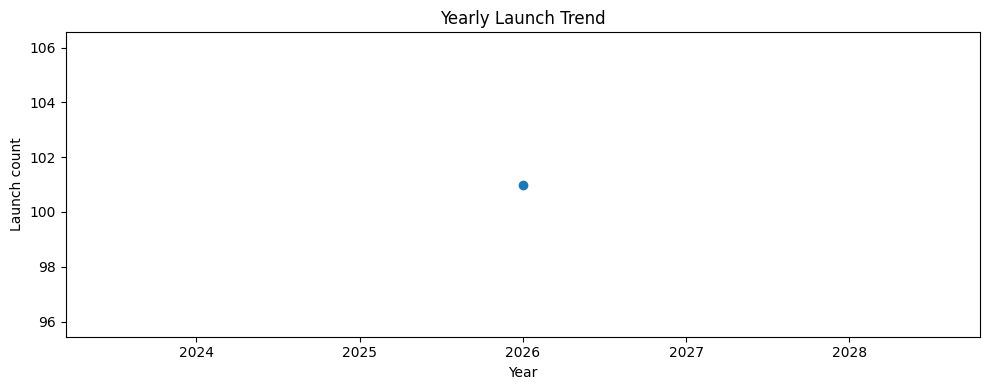

In [11]:
# 6. Monthly launches
monthly = df.dropna(subset=["date_utc"]).set_index("date_utc").resample("YS").size()
ax = monthly.plot(kind="line", marker="o", figsize=(10,4), title="Yearly Launch Trend")
ax.set_xlabel("Year"); ax.set_ylabel("Launch count")
plt.tight_layout(); plt.show()

## Results write-up template
After executing, write 3–5 observations based on the charts you actually see:
- Which year has the most launch records?
- How does the known-outcome success rate change over time?
- Which launch sites account for most records?
- Is payload mass visibly associated with outcome in this dataset?
Do not state causation from visual association alone.